In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_2bands import Moire
import utils

In [79]:
sys = Moire(theta_deg=3.5, psi_deg=40.0, V=9.2, n_shells=8)

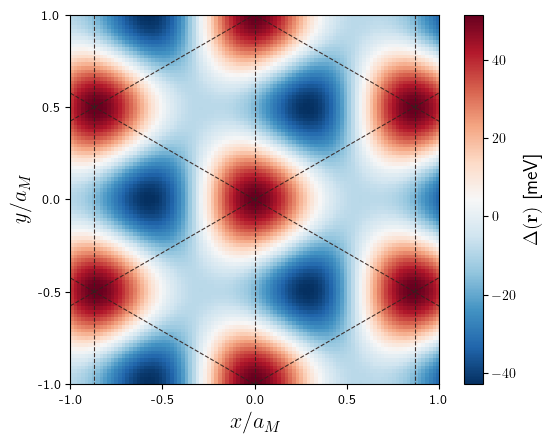

In [77]:
from matplotlib.ticker import FuncFormatter, MultipleLocator
fig, ax = plt.subplots()
scale = 1.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=100)
sys.plot_triangular_lattice(ax, extent)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta(\mathbf{r})$ [meV]", fontsize=14)

aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
#sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)
plt.savefig("plots/moire_potential.pdf", dpi=300, bbox_inches='tight')

Text(0.5, 1.0, '$\\mathbf{R}_0 = \\left(0, a_M\\right)$')

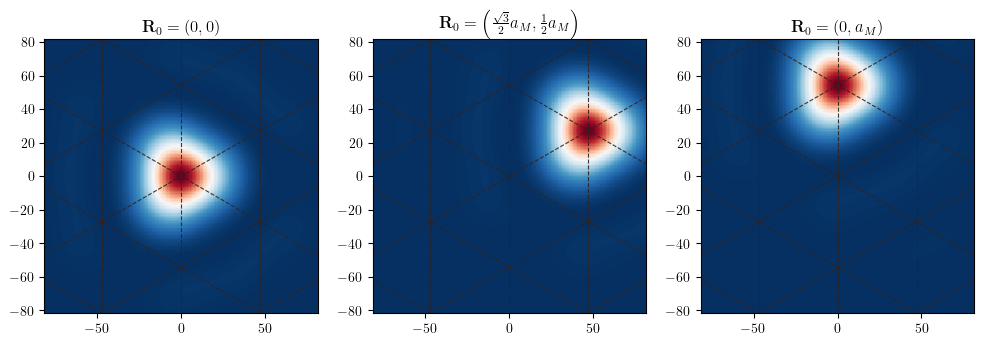

In [62]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)


fig, ax = plt.subplots(1, 3, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)
sys.plot_triangular_lattice(ax[0], extent)
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")

im = sys.plot_wannier_function(ax[1], X, Y, k_points, R0=np.array([np.sqrt(3) * sys.aM / 2, sys.aM / 2]))
sys.plot_triangular_lattice(ax[1], extent)
ax[1].set_title(r"$\mathbf{R}_0 = \left(\frac{\sqrt{3}}{2}a_M, \frac{1}{2}a_M\right)$")

im = sys.plot_wannier_function(ax[2], X, Y, k_points, R0=np.array([0.0, sys.aM]))
sys.plot_triangular_lattice(ax[2], extent)
ax[2].set_title(r"$\mathbf{R}_0 = \left(0, a_M\right)$")

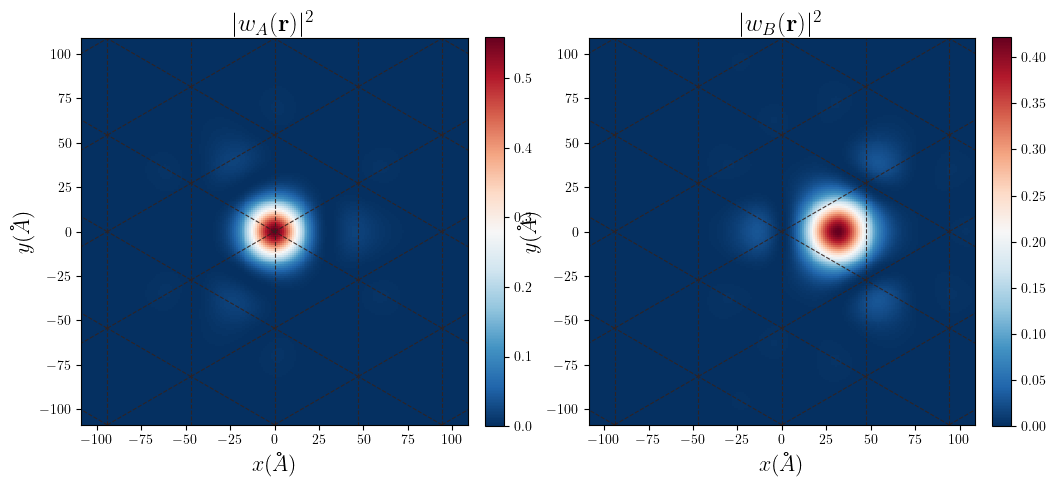

In [80]:
scale = 2.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
v2 = sys.a1.copy()
v2[1] = - v2[1]
RB = (sys.a1 + v2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)

ax[0].set_title(r"$|w_A(\mathbf{r})|^2$", fontsize=18)
ax[0].set_xlabel(r'$x (\AA)$', fontsize=16)
ax[0].set_ylabel(r'$y (\AA)$', fontsize=16)
extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction(ax[0], wannier1, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|w_B(\mathbf{r})|^2$", fontsize=18)
ax[1].set_xlabel(r'$x (\AA)$', fontsize=16)
ax[1].set_ylabel(r'$y (\AA)$', fontsize=16)
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction(ax[1], wannier2, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_two_bands.pdf", dpi=300, bbox_inches='tight')

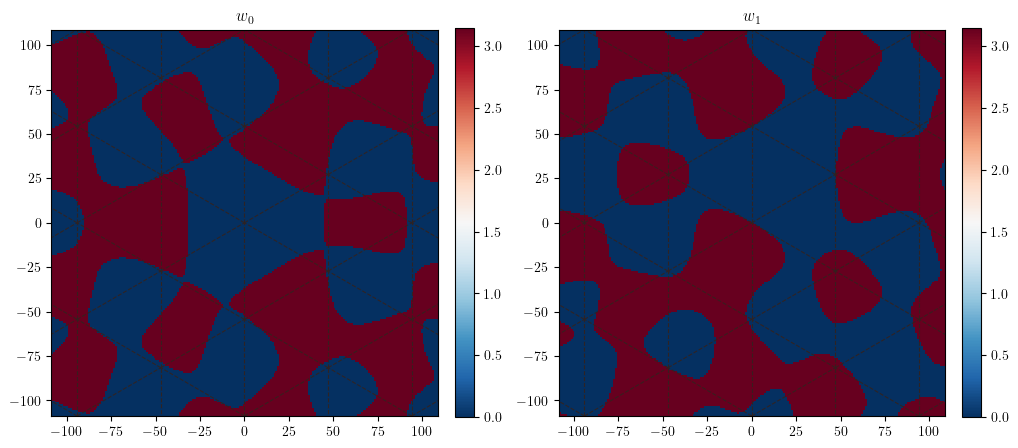

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)

ax[0].set_title(r"$w_0$")
extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction_phase(ax[0], wannier1, extent, cmap='RdBu_r')
plt.colorbar(im0, fraction=0.046, pad=0.04)

ax[1].set_title(r"$w_1$")
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction_phase(ax[1], wannier2, extent, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)

4it [05:16, 79.08s/it]


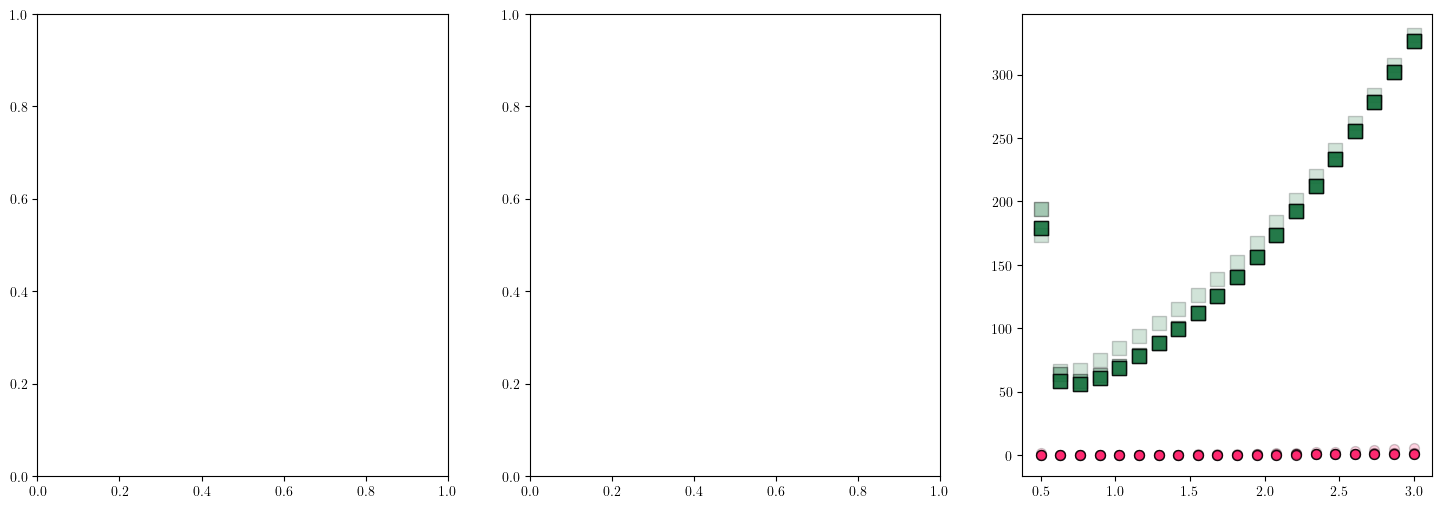

In [105]:
sys.n_shells = 10
sys.V = 6.0
thetas = np.linspace(0.5, 3.0, 20)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

scale_W = 6.0

NxR = 100
NyR = 100

NxK = 21
NyK = NxK

k_res = [3, 6, 9, 12]
k_alpha = [0.2, 0.4, 0.6, 0.8]
x_res = [30, 50, 100, 150]
x_alpha = [0.2, 0.4, 0.6, 0.8]

psi_values = [0.0, 20, 50]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, psi in zip(axes[2:], psi_values[2:]):
    sys.psi_deg = psi

    for resx, resk, alphax, alphak in tqdm(zip(x_res, k_res, x_alpha, k_alpha)):
        rW_values = []
        l0_values = []
        omega = []
        for th in thetas:
            sys.theta_deg = th

            x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, resx)
            X, Y = np.meshgrid(x, y)
            k_points = sys.mesh_k_unit_cell(Nx=NxK, Ny=NyK)

            ## Trial functions centers
            RA = np.zeros(2)
            v2 = sys.a1.copy()
            v2[1] = - v2[1]
            RB = (sys.a1 + v2) / 3

            wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

            wannier1 = wanniers[0, :, :]
            wannier2 = wanniers[1, :, :]

            fun = lambda xx, yy: (xx-RA[0])**2 + (yy-RA[1])**2
            spread1 = sys.integrate_wannier(fun, wannier1, X, Y, k_points)

            fun2 = lambda xx, yy: (xx-RB[0])**2 + (yy-RB[1])**2
            spread2 = sys.integrate_wannier(fun2, wannier2, X, Y, k_points)
            
            omega.append((spread1 + spread2) / sys.aM**2)

            # integral = sys.integrate_trace(Nx=resk, Ny=resk)
            # l0 = np.sqrt(integral)
            # l0_valuesH.append(l0)
            integral = sys.integrate_trace(Nx=resk, Ny=resk)
            l0_values.append(integral / sys.aM**2)

        ax.scatter(thetas, np.array(omega), facecolors='#197340', edgecolors='k',
                   s=100, marker='s', alpha=alphax)
        ax.scatter(thetas, np.array(l0_values), facecolors='#FF216B', edgecolors='k',
                   s=50, alpha=alphak)

(0.0, 1.0)

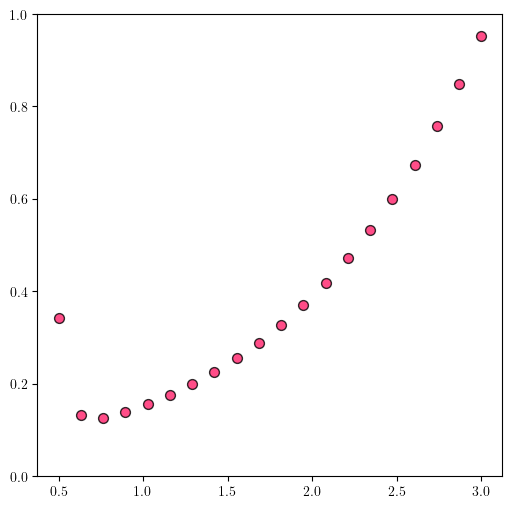

In [119]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.scatter(thetas, np.array(omega), facecolors='#197340', edgecolors='k',
            s=100, marker='s', alpha=alphax)
ax.scatter(thetas, np.array(l0_values), facecolors='#FF216B', edgecolors='k',
            s=50, alpha=alphak)
ax.set_ylim([0, 1])

### Quantum Metric

In [109]:
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
k_points = np.column_stack([KX.ravel(), KY.ravel()])
g_xx, g_xy, g_yy = sys.quantum_metric(k_points)

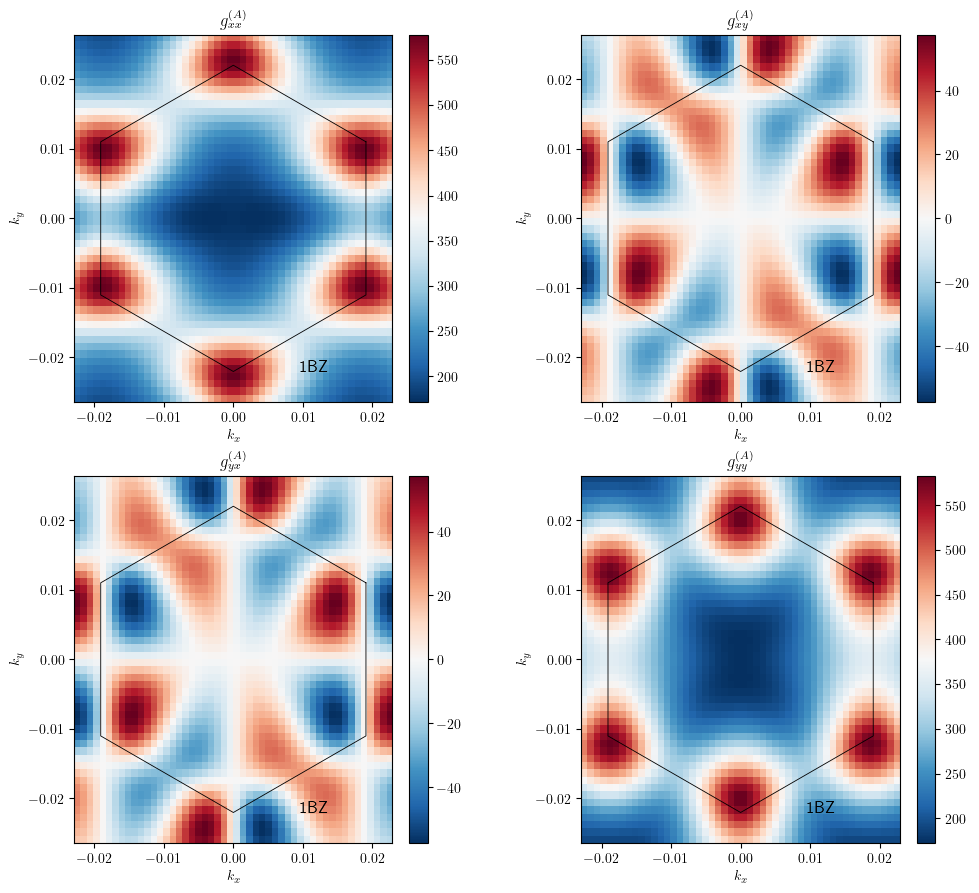

In [110]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric_band(ax, KX, KY, band=0, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric_band_A.pdf", dpi=300, bbox_inches='tight')

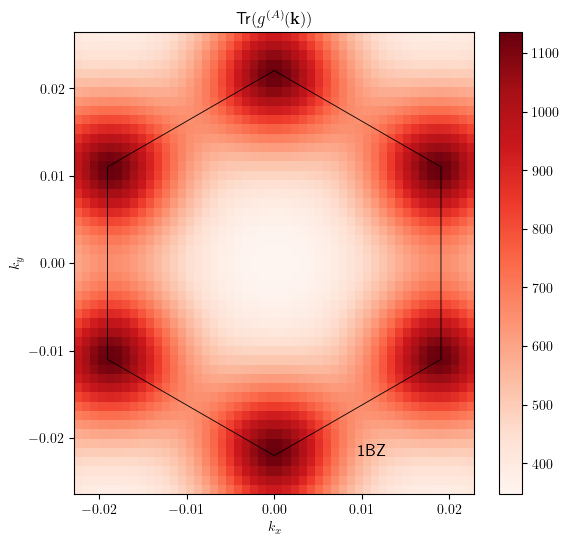

In [111]:
fig, ax = plt.subplots(figsize=(8, 6))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric_band(ax, KX, KY, band=0, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/trace_quantum_metric_band_A.pdf", dpi=300, bbox_inches='tight')

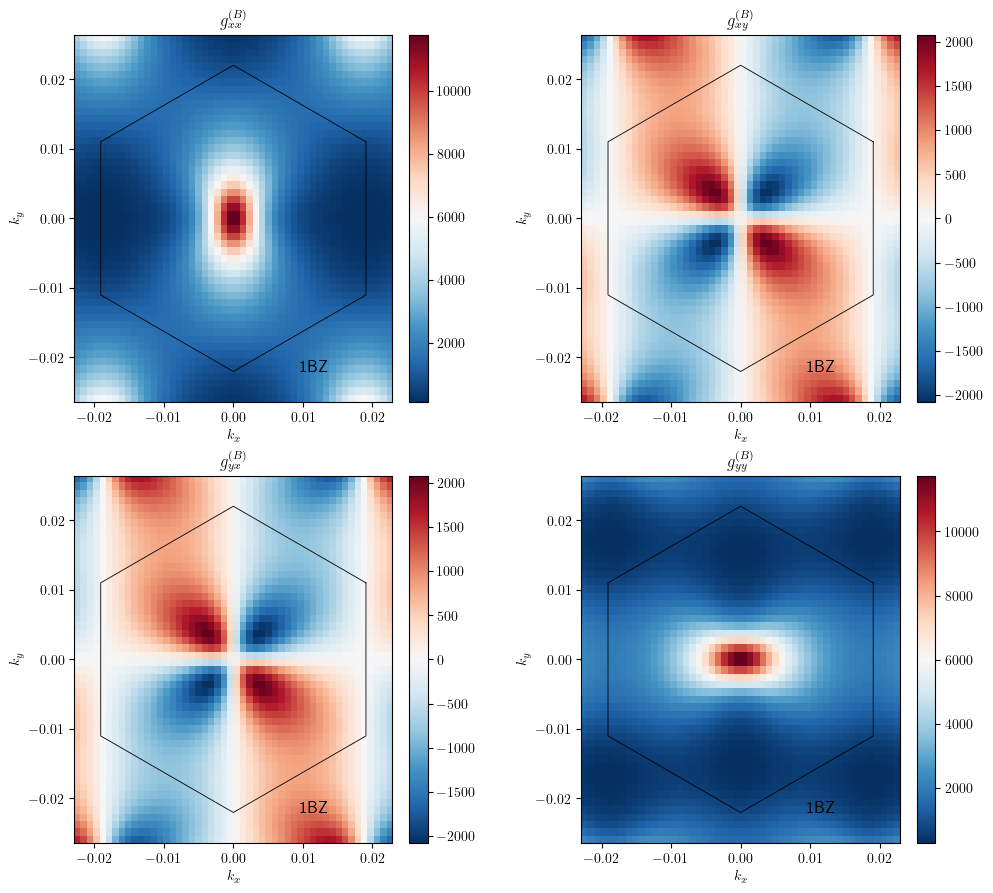

In [112]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric_band(ax, KX, KY, band=1, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric_band_B.pdf", dpi=300, bbox_inches='tight')

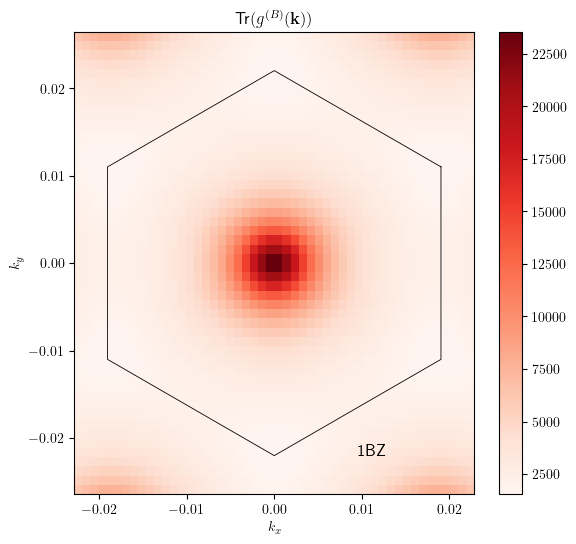

In [113]:
fig, ax = plt.subplots(figsize=(8, 6))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric_band(ax, KX, KY, band=1, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/trace_quantum_metric_band_B.pdf", dpi=300, bbox_inches='tight')